# Reproducing the numbers on any predictions

The metrics of this repository do not depend on its models. Given predictions from any source, the same functions compute the numbers the paper reports.

This notebook runs on **one slide**. As it stands that slide comes from a run of this repository, so the numbers below are real. The first cell is the only one to change: point it at your own predictions and everything after it is unchanged.

**What you need**, for one slide:

| array | shape | is |
|---|---|---|
| `y` | `(n_spots, n_genes)` | the measured expression |
| `mu` | `(n_spots, n_genes)` | the predicted expression |
| `pred_var` | `(n_spots, n_genes)` | the predicted variance, that is, the uncertainty |
| `genes` | `(n_genes,)` | the gene names |

All three matrices have to be on the same scale as each other. The paper works on `log1p` of counts per 10 000.

Five sections, in the order the paper builds them: the accuracy, the calibration, whether the uncertainty ranks the errors on either axis of the slide, the sparsification curve, and finally how per-slide numbers become a cohort headline with an interval across patients.

In [9]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

# The repository root, found by walking up until src/ appears. Nothing is installed.
PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))

# ─────────────────────────────────────────────────────────────────────────────
# THE DATA, and the only cell to change.
#
# It loads one slide of one run of this repository, of the heteroscedastic head
# on the TLS cohort, from the fold where that slide's patient was held out. To
# use your own predictions instead, assign the four names below from wherever
# they come from and leave the rest of the notebook alone.
# ─────────────────────────────────────────────────────────────────────────────
RUN   = PROJ / "results" / "TLS" / "pr_classic3" / "_TLS_hvg_top3000" / "r75" / "heteroscedastic" / "lambda_0.0"
PREDS = RUN / "predictions" / "preds_fold0.h5ad"

if not PREDS.is_file():
    raise FileNotFoundError(
        f"{PREDS} is not there. Either run the sweep first (main README), or replace "
        f"this cell with your own y / mu / pred_var / genes arrays."
    )

pred  = sc.read_h5ad(PREDS)
pred  = pred[pred.obs["split"] == "test"]              # the held-out patient of this fold
slide = pred.obs["slide"].astype(str).value_counts().idxmax()
pred  = pred[pred.obs["slide"].astype(str) == slide]   # and one slide of that patient

y        = np.asarray(pred.layers["y"], dtype=np.float64)   # measured
mu       = np.asarray(pred.X,           dtype=np.float64)   # predicted
pred_var = np.asarray(pred.layers["pred_var"], dtype=np.float64)   # predicted variance
genes    = pred.var_names.to_numpy()

n_spots, n_genes = mu.shape
print(f"slide {slide}, held out from training, of {RUN.parent.name}/{RUN.name}")
print(f"{n_spots} spots x {n_genes} genes, on the log1p(CP10k) scale")

slide KC1, held out from training, of heteroscedastic/lambda_0.0
3690 spots x 3000 genes, on the log1p(CP10k) scale


## 1. Accuracy

`compute_metrics` is the entry point for sections 1 to 3. It takes the three matrices plus one slide label per spot.

It works per (slide, gene) first and averages afterwards. That order is the point: pooling every spot of every slide into one correlation lets the differences between slides carry the score, which inflates it. Here there is a single slide, so `groups` is one repeated label.

In [10]:
from src.evaluation.metrics_slide_aware import compute_metrics

groups = np.full(n_spots, "my_slide")          # one slide label per spot

m = compute_metrics(mu, y, groups, pred_var=pred_var, corr_metrics=("pearson", "spearman"))

print("ACCURACY")
print(f"  pearson                     {m['pearson']:+.3f}   correlation of the prediction with the measurement")
print(f"  spearman                    {m['spearman']:+.3f}   the same, on ranks")
print(f"  mae_median                  {m['mae_median']:.3f}    median over genes of the absolute error")
print(f"  mse_median                  {m['mse_median']:.3f}    median over genes of the squared error")

ACCURACY
  pearson                     +0.004   correlation of the prediction with the measurement
  spearman                    +0.001   the same, on ranks
  mae_median                  0.114    median over genes of the absolute error
  mse_median                  0.098    median over genes of the squared error


Everything `compute_metrics` returns also comes per gene, under the same name with `_per_gene`, and the per (slide, gene) rows it was built from are in `m["error_per_slide_gene"]` and `m["calibration_per_slide_gene"]`. Below, the ten best-predicted genes of the slide, with the calibration and informativeness numbers of the next two sections already beside them.

In [11]:
per_gene = pd.DataFrame({
    "gene":     genes,
    "pearson":  m["pearson_per_gene"],
    "ece_pit":  m["ece_pit_per_gene"],
    "unc_err":  m["var_residual_corr_per_gene"],
    "unc_err_controlled": m["var_residual_corr_partial_per_gene"],
})
print(per_gene.sort_values("pearson", ascending=False).head(10).to_string(index=False))

    gene  pearson  ece_pit   unc_err  unc_err_controlled
  IGFBP3 0.399093 0.112637  0.245033            0.026331
  HILPDA 0.317581 0.153887  0.046709            0.115351
   C1QL1 0.315580 0.152004  0.058364            0.067457
     SCD 0.308897 0.100984  0.111153            0.053483
      C7 0.303905 0.271687  0.277854            0.255117
   PTGDS 0.281196 0.281871  0.466603            0.059102
   CRYAB 0.275015 0.278534 -0.161865           -0.087142
  TMEM91 0.259377 0.155812 -0.147718           -0.010688
     LTB 0.251307 0.258451  0.505814            0.034623
SERPINA1 0.247419 0.130452  0.017951           -0.009370


## 2. Calibration

Is the predicted distribution the right width? Three numbers say so, and all three are reductions of one curve, which is the thing to look at. For each confidence level, it asks what fraction of the measurements actually fell inside an interval of that level. A perfectly calibrated model lands on the diagonal.

`compute_metrics` returns it under `empirical_coverage`, against the levels in `confidence_levels`. It is computed per (slide, gene) like everything else, then averaged.

Below the diagonal means the intervals are too narrow, the model is over-confident. Above means the opposite. `ece_pit` is the mean distance to the diagonal, `disp_signed` says which side of it, and `pit_bias` says whether the predictions sit above or below the measurements rather than being the wrong width.

CALIBRATION
  ece_pit      0.208    mean distance to the diagonal, 0 is perfect
  disp_signed  -0.097   positive = too confident, negative = too cautious
  pit_bias     +0.087   the predictions sit above (+) or below (-) the measurements
  level   covered     gap
     5%      1.6%   -3.4%
    20%      8.2%  -11.8%
    35%     27.6%   -7.4%
    50%     83.2%  +33.2%
    65%     94.1%  +29.1%
    80%     95.0%  +15.0%
    95%     95.9%   +0.9%


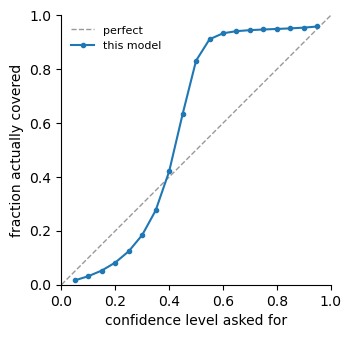

In [12]:
print("CALIBRATION")
print(f"  ece_pit      {m['ece_pit']:.3f}    mean distance to the diagonal, 0 is perfect")
print(f"  disp_signed  {m['disp_signed']:+.3f}   positive = too confident, negative = too cautious")
print(f"  pit_bias     {m['pit_bias']:+.3f}   the predictions sit above (+) or below (-) the measurements")

conf = m["confidence_levels"]
cov  = m["empirical_coverage"]

print(f"{'level':>7}{'covered':>10}{'gap':>8}")
for q in range(0, len(conf), 3):
    print(f"{conf[q]:>7.0%}{cov[q]:>10.1%}{cov[q] - conf[q]:>+8.1%}")

fig, ax = plt.subplots(figsize=(3.6, 3.6))
ax.plot([0, 1], [0, 1], color="0.6", lw=1, ls="--", label="perfect")
ax.plot(conf, cov, color="C0", marker="o", ms=3, label="this model")
ax.set_xlabel("confidence level asked for")
ax.set_ylabel("fraction actually covered")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 3. Informativeness, on both axes

Does the uncertainty know where the errors are? The question is asked twice, because a slide is a matrix and there are two ways to hold one thing fixed.

- **Gene axis.** One gene at a time, across the spots of the slide. Does this gene's uncertainty rise where this gene's error rises?
- **Spot axis.** One spot at a time, across the genes. Its exact dual.

Both are needed because a head is blind on the axis along which its uncertainty is constant. A head with one variance per gene has nothing to say along the gene axis and everything to say along the spot axis; a head with one variance per spot is the mirror image. Reporting one axis only would leave such a head unmeasured for a reason about the axis, not about the head.

`compute_metrics` already gave the gene axis, as `var_residual_corr` and its `_partial` companion. This section computes both axes explicitly, because the two together are what the paper reports.

Each axis is reported twice more, **naive** and **controlled**:

- naive is Spearman between the uncertainty and the absolute error, inside the group;
- controlled is the same with the predicted mean partialled out, `_safe_partial_spearman(u, error, mu)`.

The gap between them is the point of the whole exercise. Errors grow with the predicted level, and so does most uncertainty, so a head can score well naively while saying nothing the predicted mean did not already say. Only the controlled number answers the question that was asked.

Two populations are shown. **all entries** keeps the zeros; **y > 0** keeps only the measured ones. Read the naive number of the first with care: where `y = 0` the error IS the prediction, `|mu - 0| = |mu|`, so on those entries the error is a function of the mean alone and the naive correlation drifts mechanically toward the mean-uncertainty coupling. That is a demonstration of the confound rather than a measurement.

In [13]:
from scipy.stats import spearmanr
from src.evaluation.metrics_slide_aware import _safe_partial_spearman

N_MIN = 60          # a group below this is dropped: the correlation would be noise

u = np.sqrt(pred_var)        # the uncertainty doing the ranking
D = np.abs(mu - y)           # the error it is asked about


def one_axis(axis, keep):
    """One row per group, along `axis`, over the entries `keep` selects.

    axis "gene" groups by column (a gene, across the slide's spots), axis "spot" by
    row (a spot, across the genes). `keep` is a boolean mask of the same shape.
    """
    rows = []
    n_groups = mu.shape[1] if axis == "gene" else mu.shape[0]
    for g in range(n_groups):
        sel = keep[:, g] if axis == "gene" else keep[g, :]
        if sel.sum() < N_MIN:
            continue
        uu = (u[:, g] if axis == "gene" else u[g, :])[sel]
        dd = (D[:, g] if axis == "gene" else D[g, :])[sel]
        mm = (mu[:, g] if axis == "gene" else mu[g, :])[sel]
        rows.append({
            "group":      g,
            "n":          int(sel.sum()),
            "naive":      spearmanr(uu, dd).statistic,
            "controlled": _safe_partial_spearman(uu, dd, mm),
        })
    return pd.DataFrame(rows)


populations = {"all entries": np.ones_like(mu, dtype=bool), "y > 0": y > 0}

print(f"{'population':>12}{'axis':>7}{'groups':>8}{'naive':>9}{'controlled':>12}")
axis_frames = {}
for pop, keep in populations.items():
    for axis in ("gene", "spot"):
        t = one_axis(axis, keep)
        axis_frames[(pop, axis)] = t
        # One slide, so both axes reduce to a plain mean over the groups. Across several
        # slides the gene axis folds slides into a gene first, weighted by n; the last
        # section of this notebook does that.
        print(f"{pop:>12}{axis:>7}{len(t):>8}"
              f"{t['naive'].mean():>+9.3f}{t['controlled'].mean():>+12.3f}")

  population   axis  groups    naive  controlled
 all entries   gene    3000   +0.077      +0.005
 all entries   spot    3690   +0.874      +0.233
       y > 0   gene    1404   -0.085      -0.092
       y > 0   spot    3609   -0.770      -0.063


**Reading it.** A controlled number near zero says the uncertainty carries nothing beyond the predicted mean, whatever the naive number says. A controlled number that stays close to the naive one says the uncertainty is genuinely tracking the error.

A `NaN` controlled value is an answer, not a failure: it means the uncertainty is constant, or a monotone function of the mean, inside that group. The partial correlation is undefined there by construction, which is exactly what happens to a per-gene variance along the gene axis.

`groups` is how many genes or spots survived the floor of 60 entries. A number far below the total is worth knowing before reading the mean next to it.

## 4. The sparsification curve

A model that knows where it is wrong should improve when it is allowed to abstain. Withhold the least certain predictions, recompute the error of the ones left, and plot that against the fraction withheld. A useful uncertainty makes the curve fall.

The curve is drawn against three others, and those comparisons are what make it readable:

- **oracle**, withholding by the true error. The best any ranking could do, so it is the floor.
- **mu high** and **mu low**, withholding by the predicted mean alone. This is the baseline a practitioner already has with no uncertainty head at all. An uncertainty that does not beat it is redundant.

Removal happens **inside each gene**, not over the whole slide at once. Pooled removal lets a model score well by knowing which genes are hard rather than which predictions are wrong, which is a different and much easier thing to know.

In [14]:
from src.evaluation.sparsification import spars_scores, per_group_curves

# One row per (spot, gene) pair, which is what the curve is computed on.
gene_idx = np.tile(np.arange(n_genes), n_spots)                  # which gene each row belongs to
err      = np.abs(mu - y).ravel().astype(np.float64)             # the error being reduced
unc      = np.sqrt(pred_var).ravel().astype(np.float64)          # the score doing the ranking
mu_flat  = mu.ravel().astype(np.float64)

fracs = np.linspace(0.0, 0.9, 19)          # withhold 0 %, 5 %, ... 90 %

curves, divisors = per_group_curves(
    keys     = {"gene": gene_idx},         # the grouping column
    values   = {"uncertainty": unc, "err_lin": err, "mu": mu_flat},
    err      = err,
    scores   = spars_scores("err_lin"),    # the four removal orders
    fracs    = fracs,
    rm_cols  = ["gene"],                   # remove inside each gene
    agg_code = gene_idx.astype(np.float64),   # one curve per gene
    n_agg    = n_genes,
)

# One curve per gene; average them into one curve per removal order.
mean_curve = {name: np.nanmean(C, axis=0) for name, C in curves.items()}

print("fraction withheld -> error of what is left, as a fraction of the error at 0 %")
print(f"{'withheld':>9}  {'uncertainty':>12}{'oracle':>9}{'mu high':>9}{'mu low':>9}")
for q in range(0, len(fracs), 3):
    print(f"{fracs[q]:>8.0%}  {mean_curve['pred'][q]:>12.3f}{mean_curve['oracle'][q]:>9.3f}"
          f"{mean_curve['mu_high'][q]:>9.3f}{mean_curve['mu_low'][q]:>9.3f}")

fraction withheld -> error of what is left, as a fraction of the error at 0 %
 withheld   uncertainty   oracle  mu high   mu low
      0%         1.000    1.000    1.000    1.000
     15%         0.963    0.583    0.880    1.052
     30%         0.947    0.482    0.808    1.125
     45%         0.943    0.400    0.757    1.218
     60%         0.946    0.327    0.725    1.342
     75%         0.961    0.254    0.707    1.512
     90%         0.984    0.166    0.714    1.815


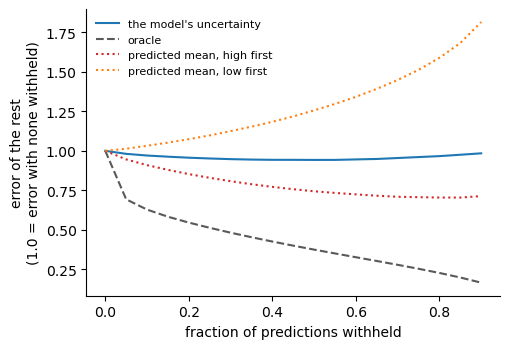

In [15]:
fig, ax = plt.subplots(figsize=(5.2, 3.6))
style = {"pred":    ("the model's uncertainty", "C0", "-"),
         "oracle":  ("oracle",                  "0.35", "--"),
         "mu_high": ("predicted mean, high first", "C3", ":"),
         "mu_low":  ("predicted mean, low first",  "C1", ":")}
for name, (label, color, ls) in style.items():
    ax.plot(fracs, mean_curve[name], color=color, ls=ls, label=label)
ax.set_xlabel("fraction of predictions withheld")
ax.set_ylabel("error of the rest\n(1.0 = error with none withheld)")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

**Reading it.** The uncertainty curve should sit below the two `mu` curves and above the oracle. Below `mu` means the uncertainty says something the predicted mean did not; above the oracle is simply the ceiling, since the oracle withholds by the true error. A curve that rises means the uncertainty is ranking the errors backwards.

`per_group_curves` returns one curve per gene, so any grouping can be rebuilt from `curves` without recomputing. `pooled_curves`, in the same module, is the version that sorts every prediction at once; the paper reports it in a table but never draws it, for the reason given above.

To go further, `snake/scripts/canals/canal2_uncertainty_precompute.py` is the production version of this notebook: the same two functions, on whole cohorts, with the mean-controlled variants and the per-slide bookkeeping.

## 5. From one slide to the whole cohort

Everything above was one slide. The paper reports a cohort of several patients, and the way those numbers are put together is itself a choice, made twice.

**First fold: slides.** A statistic is never pooled across slides. It is computed inside one (slide, gene) and averaged afterwards. Pooling every spot of every slide into one correlation would let the differences between slides carry the score, which inflates it without the model having learned anything. The gene axis then folds a gene's slides into that gene **weighted by the number of entries**, and averages the genes with no weight. The spot axis has nothing to fold, since a spot belongs to exactly one slide, so it is a plain mean over spots.

**Second fold: patients.** The cross-validation is leave-one-patient-out: each patient is the test set exactly once, under a model that never saw it. That gives K numbers, one per patient, and the headline is their mean. The spread across patients is the honest uncertainty on that headline, so it is reported as a Student-t interval on K points, not as a standard error over spots or genes, of which there are thousands and which would give an interval far too narrow.

The cell below does both folds on made-up inputs, so that the shape of each step is visible.

In [16]:
from scipy.stats import t as student_t

# ── Fold 1: (slide, gene) rows -> one number per gene -> one number per slide-set ──
# Made-up rows, as the analysis would have them: one per (slide, gene), with n entries.
rows = pd.DataFrame({
    "slide": ["A", "A", "B", "B", "C", "C"],
    "gene":  ["g1", "g2", "g1", "g2", "g1", "g2"],
    "n":     [400, 120, 380, 90, 410, 150],
    "value": [0.31, 0.22, 0.28, 0.19, 0.35, 0.25],
})

per_gene = (rows.assign(wv=rows["value"] * rows["n"])
                .groupby("gene", as_index=False)[["wv", "n"]].sum())
per_gene["value"] = per_gene["wv"] / per_gene["n"]      # slides folded, weighted by n
gene_axis = per_gene["value"].mean()                    # genes averaged, unweighted

print("per gene, slides folded weighted by n:")
print(per_gene[["gene", "value"]].to_string(index=False))
print(f"gene axis for this set of slides: {gene_axis:.3f}\n")

# ── Fold 2: one number per held-out patient -> the headline and its interval ──────
per_donor = np.array([0.31, 0.27, 0.34, 0.22, 0.29, 0.30])   # K = 6, one per patient
K    = len(per_donor)
mean = per_donor.mean()
sd   = per_donor.std(ddof=1)
sem  = sd / np.sqrt(K)
tcrit = student_t.ppf(0.975, df=K - 1)

ci = (mean - tcrit * sem, mean + tcrit * sem)                        # on the mean
pi = (mean - tcrit * sd * np.sqrt(1 + 1 / K),                        # for a new patient
      mean + tcrit * sd * np.sqrt(1 + 1 / K))

print(f"{K} patients: {np.round(per_donor, 3).tolist()}")
print(f"headline            {mean:.3f}")
print(f"spread across them  sd {sd:.3f}   sem {sem:.3f}")
print(f"95% interval on the mean       [{ci[0]:.3f}, {ci[1]:.3f}]")
print(f"95% interval for a new patient [{pi[0]:.3f}, {pi[1]:.3f}]")

per gene, slides folded weighted by n:
gene    value
  g1 0.314202
  g2 0.225000
gene axis for this set of slides: 0.270

6 patients: [0.31, 0.27, 0.34, 0.22, 0.29, 0.3]
headline            0.288
spread across them  sd 0.041   sem 0.017
95% interval on the mean       [0.246, 0.331]
95% interval for a new patient [0.175, 0.401]


The two intervals answer different questions. The first says how well the mean itself is pinned down; the second says what a new patient would plausibly give, and it is much wider. A paper that reports only the first, on six patients, is reporting the easier of the two.

One caveat belongs with them. The K folds share most of their training patients, so the K numbers are not independent and both intervals are optimistic. That is inherent to leave-one-patient-out at small K, and the reason the per-patient numbers are always shown next to the interval rather than replaced by it.